# Baseline Ingênuo — Classe Majoritária

Este notebook tem como objetivo estabelecer um modelo de referência (*baseline*) para o problema de classificação do resultado de partidas de *League of Legends*.

Será utilizado o método da **classe majoritária**, que consiste em identificar a classe mais frequente no conjunto de treinamento e utilizá-la como previsão para todas as partidas do conjunto de teste. Dessa forma, o método não considera as características das partidas, servindo como uma referência simples de desempenho.

Os resultados serão avaliados por meio de métricas de classificação e utilizados como referência para comparação com os modelos de Aprendizado de Máquina desenvolvidos posteriormente, especialmente Random Forest e XGBoost.

Essa comparação permitirá verificar se os modelos conseguem aprender padrões relevantes dos dados e obter resultados superiores a uma estratégia que considera apenas a frequência das classes.

In [ ]:
import pandas as pd

# Caminho do dataset
DATASET_PATH = "../data/team-time-series-10000.xlsx"

# Configuração para reprodutibilidade
SEED = 42

# Carregamento dos dados
df = pd.read_excel(DATASET_PATH)

# Verificação inicial
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")

display(df.head())

Dimensões do dataset: 289264 linhas e 108 colunas


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [2]:
# Seleciona uma única observação por partida
partidas = df.drop_duplicates(subset="match_id")

# Quantidade de partidas por classe
distribuicao = partidas["vencedor"].value_counts().sort_index()

nomes_equipes = {
    100: "Equipe Azul",
    200: "Equipe Vermelha"
}

for classe, quantidade in distribuicao.items():
    equipe = nomes_equipes.get(classe, f"Classe {classe}")
    percentual = (quantidade / len(partidas)) * 100

    print(f"{equipe}: {quantidade} partidas ({percentual:.2f}%)")

print(f"\nTotal de partidas: {len(partidas)}")


Equipe Azul: 4601 partidas (46.01%)
Equipe Vermelha: 5399 partidas (53.99%)

Total de partidas: 10000


In [4]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/

In [ ]:
from sklearn.model_selection import train_test_split

# Uma observação por partida, preservando a ordem original
partidas = df.drop_duplicates(subset="match_id").copy()

# Separação das partidas e seus respectivos resultados
X = partidas[["match_id"]]
y = partidas["vencedor"]

# Divisão em treinamento (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED, #Para reprodutibilidade
    stratify=y
)

print(f"Partidas para treinamento: {len(X_train)}")
print(f"Partidas para teste: {len(X_test)}")


Partidas para treinamento: 7000
Partidas para teste: 3000


In [6]:
from sklearn.dummy import DummyClassifier

# Criação do modelo baseline
baseline = DummyClassifier(strategy="most_frequent")

# Treinamento utilizando apenas os rótulos
baseline.fit(X_train, y_train)

# Identificação da classe escolhida pelo modelo
classe_majoritaria = baseline.classes_[baseline.class_prior_.argmax()]

nomes_equipes = {
    100: "Equipe Azul",
    200: "Equipe Vermelha"
}

print(f"Classe majoritária: {nomes_equipes[classe_majoritaria]}")
print(f"Valor da classe: {classe_majoritaria}")


Classe majoritária: Equipe Vermelha
Valor da classe: 200


In [7]:
# Realização das previsões
y_pred = baseline.predict(X_test)

# Exibição das primeiras previsões
print("Primeiras 10 previsões:")
print(y_pred[:10])

# Quantidade de previsões por classe
predicoes = pd.Series(y_pred).value_counts().sort_index()

nomes_equipes = {
    100: "Equipe Azul",
    200: "Equipe Vermelha"
}

print("\nDistribuição das previsões:")

for classe, quantidade in predicoes.items():
    equipe = nomes_equipes.get(classe, f"Classe {classe}")
    print(f"{equipe}: {quantidade} previsões")


Primeiras 10 previsões:
[200 200 200 200 200 200 200 200 200 200]

Distribuição das previsões:
Equipe Vermelha: 3000 previsões


F1-score (Macro): 0.3506
Balanced Accuracy: 0.5000

Relatório de classificação:
                 precision    recall  f1-score   support

    Equipe Azul       0.00      0.00      0.00      1380
Equipe Vermelha       0.54      1.00      0.70      1620

       accuracy                           0.54      3000
      macro avg       0.27      0.50      0.35      3000
   weighted avg       0.29      0.54      0.38      3000



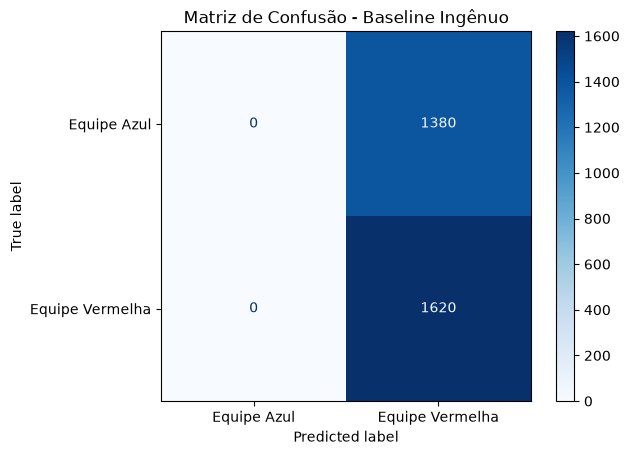

In [8]:
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Cálculo das métricas
f1 = f1_score(y_test, y_pred, average="macro")
balanced_acc = balanced_accuracy_score(y_test, y_pred)

print(f"F1-score (Macro): {f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

# Relatório de classificação
print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred,
    labels=[100, 200],
    target_names=["Equipe Azul", "Equipe Vermelha"],
    zero_division=0
))

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=[100, 200])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Equipe Azul", "Equipe Vermelha"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Baseline Ingênuo")
plt.show()


In [9]:
# Relatório do Baseline Ingênuo

print("=" * 55)
print("           RELATÓRIO - BASELINE INGÊNUO")
print("=" * 55)

print(f"\nTotal de partidas: {len(partidas)}")
print(f"Partidas para treinamento: {len(X_train)}")
print(f"Partidas para teste: {len(X_test)}")

print("\nClasse majoritária:")
print(f"  Equipe vencedora prevista: {nomes_equipes[classe_majoritaria]}")
print(f"  Identificador: {classe_majoritaria}")

print("\nDistribuição real no conjunto de teste:")
for classe, quantidade in y_test.value_counts().sort_index().items():
    equipe = nomes_equipes[classe]
    percentual = quantidade / len(y_test) * 100
    print(f"  {equipe}: {quantidade} ({percentual:.2f}%)")

print("\nMétricas de avaliação:")
print(f"  Accuracy:           {(y_test == y_pred).mean():.4f}")
print(f"  F1-score (Macro):   {f1:.4f}")
print(f"  Balanced Accuracy:  {balanced_acc:.4f}")

print("\nConclusão:")
print(
    f"  O baseline prevê todas as partidas como vitória da "
    f"{nomes_equipes[classe_majoritaria].lower()}."
)
print(
    f"  Seu F1-score Macro foi {f1:.4f} e sua Balanced Accuracy "
    f"foi {balanced_acc:.4f}."
)

print("\n" + "=" * 55)


           RELATÓRIO - BASELINE INGÊNUO

Total de partidas: 10000
Partidas para treinamento: 7000
Partidas para teste: 3000

Classe majoritária:
  Equipe vencedora prevista: Equipe Vermelha
  Identificador: 200

Distribuição real no conjunto de teste:
  Equipe Azul: 1380 (46.00%)
  Equipe Vermelha: 1620 (54.00%)

Métricas de avaliação:
  Accuracy:           0.5400
  F1-score (Macro):   0.3506
  Balanced Accuracy:  0.5000

Conclusão:
  O baseline prevê todas as partidas como vitória da equipe vermelha.
  Seu F1-score Macro foi 0.3506 e sua Balanced Accuracy foi 0.5000.

